# Lecture 5. CVXPy

**Convex optimization, Fall 2026**

- Lectures 2 and 4 built a grammar and a reduction. 
- An expression is DCP when every atom is used with the curvature, sign, and monotonicity that atom declared. 
- Each accepted atom then contributes the cone representation of its epigraph, and the solver receives one cone program.

CVXPy is that grammar and that reduction, embedded in Python, with a cone solver on the end.

The modeling question: which problems the grammar accepts as written, which become acceptable after a rewrite that preserves the minimizer, and which no rewrite inside this library can express.


## Plan

1. The pipeline, from an expression tree to a primal-dual pair
2. Accepted as written
3. Equivalent rewrites: another atom, a geometric program, and quasiconvex objectives (a cost ratio, a Sharpe ratio, a condition number)
4. A refusal, which is final, and a relaxation that rewrites it: the MaxCut spectrahedron from lecture 1
5. Three models: a piecewise-constant signal, a conditional-independence graph, and pre-cooling an office

Notation is lecture 1's. Vectors and matrices are bold. $p^\star$ is the optimal value.

Every code cell uses CLARABEL, except the integer program, which is handed to HiGHS.


In [1]:
%matplotlib inline
import numpy as np
import cvxpy as cp
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)
plt.rcParams.update(
    {
        "figure.figsize": (7.2, 4.0),
        "axes.grid": True,
        "grid.alpha": 0.3,
        "font.size": 12,
        "axes.titlesize": 13,
        "legend.fontsize": 11,
    }
)


# The pipeline

A problem is an expression tree.

- Leaves are variables, constants, and parameters.
- Internal nodes are atoms: `sum_squares`, `inv_pos`, `log_det`, a sum, a product, an index.

Lecture 2 attached three attributes to every atom: 
- curvature
- sign
- monotonicity 

in each argument. 
CVXPy reads those attributes and nothing else. It does not look at a Hessian.

`solve` then does four things.

- **Check.** 
    - Walk the tree. 
    - The objective must be convex to minimize or concave to maximize. 
    - An inequality must have convex lesser side. 
    - An equality must be affine. 
    - A failure raises `DCPError` before any solver starts.
- **Canonicalize.**  
    - Replace each accepted atom by its graph implementation: 
        - new coordinates
        - cone membership. 
    - Lecture 4 built these cones. 
    - The reduction is called `Dcp2Cone`.
- **Stuff.** 
    - Stack the cone memberships into one product cone and one affine map. 
    - A quadratic objective can stay quadratic; otherwise the objective that reaches the solver is linear, with a single $1$ on the epigraph coordinate.
- **Solve and recover.** The solver returns a primal point, a dual point, and a status. CVXPy writes them to `variable.value` and `constraint.dual_value`.

## A delay budget, written two ways

Three services run in series. Service $i$ is given a replication level $x_i>0$. Its delay is $d_i/x_i$ and its cost is $c_i x_i$. A request must finish by a deadline $T$.

$$
\begin{aligned}
\mathrm{minimize}&\quad \mathbf{c}^\top\mathbf{x}\\
\mathrm{subject\ to}&\quad \sum_i d_i/x_i \le T, \qquad \mathbf{x}>\mathbf{0}.
\end{aligned}
$$

On $\mathbf{x}>\mathbf{0}$ the constraint function is convex: 
- $1/x_i$ is convex there
- a nonnegative combination of convex functions is convex. 

The expression `d / x` does not declare that convexity. Its curvature attribute is log-log convex.


## Log-log convex

Two logarithms: one on the value, one on the argument.

Take $\mathbf{x}>\mathbf{0}$ and set $\mathbf{x}=e^{\mathbf{y}}$ componentwise, so $\mathbf{y}=\log\mathbf{x}$ is free in $\mathbb{R}^n$. A positive function $f$ is **log-log convex** when

$$
\mathbf{y}\mapsto \log f(e^{\mathbf{y}})
$$

is convex. It is **log-log affine** when this map is affine, and **log-log concave** when the map is concave.

A monomial $c\, x_1^{a_1}\cdots x_n^{a_n}$ with $c>0$ is log-log affine:

$$
\log\bigl(c\, e^{\mathbf{a}^\top\mathbf{y}}\bigr)=\log c+\mathbf{a}^\top\mathbf{y}.
$$

A **posynomial**, a sum of monomials, is log-log convex. The log of the sum is

$$
\log\sum_k \exp(\log c_k+\mathbf{a}_k^\top\mathbf{y}),
$$

a log-sum-exp of affine functions, the convex atom from lecture 2. The sum of two monomials with different exponents is not itself a monomial, so the map is convex and not affine.

For the delay budget, $d_i/x_i=d_i\, e^{-y_i}$ is a monomial, and

$$
\log\sum_i d_i\, e^{-y_i}=\log\sum_i\exp(\log d_i-y_i)
$$

is convex. The sum $\sum_i d_i/x_i$ is log-log convex. The checker stores that attribute and no DCP curvature. The next cell prints `LOG-LOG CONVEX`, `DGP True`, and `DCP False`.

Convexity of $\sum_i d_i/x_i$ as a function of $\mathbf{x}$, on $\mathbf{x}>\mathbf{0}$, is a separate fact. The spelling `d / x` does not carry it. `gp=True`, below, is this definition as a reduction: substitute $\mathbf{y}=\log\mathbf{x}$ and hand the convex function $\log f(e^{\mathbf{y}})$ to the cone pipeline.


In [2]:
# Division of a positive variable is a posynomial, and the DCP checker rejects it.
d = np.array([1.0, 4.0, 0.25])
c = np.array([1.0, 1.0, 2.0])
T = 3.0

x = cp.Variable(3, pos=True)
delay = cp.sum(d / x)
spelled = cp.Problem(cp.Minimize(c @ x), [delay <= T])
print(f"curvature of d/x    {delay.curvature}")
print(f"DCP {spelled.is_dcp()}     DGP {spelled.is_dgp()}     DQCP {spelled.is_dqcp()}")
try:
    spelled.solve(solver=cp.CLARABEL)
except cp.DCPError as err:
    print(err)


curvature of d/x    LOG-LOG CONVEX
DCP False     DGP True     DQCP False
Problem does not follow DCP rules. Specifically:
The following constraints are not DCP:
Sum([1.   4.   0.25] / var1, None, False) <= 3.0 , because the following subexpressions are not:
|--  [1.   4.   0.25] / var1
However, the problem does follow DGP rules. Consider calling solve() with `gp=True`.


## The atom that carries the curvature

`inv_pos` is the same map $x\mapsto 1/x$ on $x>0$, with curvature declared convex and decreasing. The constraint becomes DCP.

Its graph implementation is a second-order cone. For $x>0$,

$$
t \ge 1/x \quad\Longleftrightarrow\quad \bigl\lVert(2,\, x-t)\bigr\rVert_2 \le x+t,
$$

up to the scaling CVXPy chooses, and that is a 3-dimensional second-order cone. Three services produce three such cones.

Lecture 3's stationarity condition has a closed form here. The deadline binds, and the multiplier $\lambda\ge 0$ on $\sum_i d_i/x_i\le T$ satisfies

$$
c_i = \lambda\, d_i/x_i^2.
$$

Solving with the tight deadline,

$$
x_i = \sqrt{d_i/c_i}\cdot s/T, \qquad s = \sum_j \sqrt{d_j c_j}, \qquad \lambda = s^2/T^2.
$$

The optimal cost is $p^\star = s^2/T$, so

$$
\frac{\partial p^\star}{\partial T} = -\lambda.
$$

CVXPy's `dual_value` on the deadline constraint is this $\lambda$. A longer deadline is worth $\lambda$ units of cost per unit of time.


In [3]:
# inv_pos is DCP. The reduction emits one second-order cone per reciprocal.
x = cp.Variable(3, pos=True)
deadline = d @ cp.inv_pos(x) <= T
budget = cp.Problem(cp.Minimize(c @ x), [deadline])
budget.solve(solver=cp.CLARABEL)

data, chain, _ = budget.get_problem_data(cp.CLARABEL)
print([type(step).__name__ for step in chain.reductions])
print(data["dims"])
print(f"status {budget.status}")
print(f"cost {budget.value:.6f}    replicas {np.array2string(x.value, precision=4)}")
print(f"deadline slack {T - d @ (1 / x.value):.2e}    dual λ {deadline.dual_value:.6f}")

s = np.sum(np.sqrt(d * c))
lam = s**2 / T**2
x_closed = np.sqrt(d / c) * s / T
print(f"closed form  cost {s**2 / T:.6f}    replicas {np.array2string(x_closed, precision=4)}    λ {lam:.6f}")
print(f"max |x - x_closed| {np.max(np.abs(x.value - x_closed)):.2e}")


def optimal_cost(deadline_value):
    replicas = cp.Variable(3, pos=True)
    problem = cp.Problem(cp.Minimize(c @ replicas), [d @ cp.inv_pos(replicas) <= deadline_value])
    problem.solve(solver=cp.CLARABEL)
    return problem.value


step = 1e-3
difference = (optimal_cost(T + step) - optimal_cost(T)) / step
print(f"finite difference of p* {difference:.4f}    -λ {-deadline.dual_value:.4f}")


['Dcp2Cone', 'CvxAttr2Constr', 'ConeMatrixStuffing', 'CLARABEL']
0 equalities, 4 inequalities, 0 exponential cones, 
SOC constraints: [3, 3, 3], PSD constraints: [],
 3d power cones [].
status optimal
cost 4.580880    replicas [1.2357 2.4715 0.4369]
deadline slack -1.15e-08    dual λ 1.526979
closed form  cost 4.580880    replicas [1.2357 2.4714 0.4369]    λ 1.526960
max |x - x_closed| 5.00e-05
finite difference of p* -1.5265    -λ -1.5270


## The same budget as a geometric program

- `d / x` was rejected as DCP and marked DGP. 
- A **geometric program** minimizes a posynomial, subject to posynomial inequalities and monomial equalities, in positive variables. 
- A posynomial is a sum of monomials $c\, x_1^{a_1}\cdots x_n^{a_n}$ with $c>0$.

- `solve(gp=True)` inserts a reduction `Dgp2Dcp` in front of the same pipeline. 
- The change of variables $y_i=\log x_i$ turns a posynomial inequality into a convex exponential-cone constraint. 
- That is the definition of log-log convexity: $\log f(e^{\mathbf{y}})$ is a convex function of $\mathbf{y}$. 
- The minimizer is mapped back to $\mathbf{x}$.

**This is an equivalent rewrite!**

- The feasible set and the optimal replication are the ones of the `inv_pos` form.
- The cone program is a different one, and its multipliers are prices on the transformed constraints.


In [4]:
# gp=True runs Dgp2Dcp and then the same cone pipeline. The dual is not λ.
x_gp = cp.Variable(3, pos=True)
gp_deadline = cp.sum(d / x_gp) <= T
geometric = cp.Problem(cp.Minimize(c @ x_gp), [gp_deadline])
geometric.solve(gp=True, solver=cp.CLARABEL)

data_gp, chain_gp, _ = geometric.get_problem_data(cp.CLARABEL, gp=True)
print([type(step).__name__ for step in chain_gp.reductions])
print(data_gp["dims"])
print(f"status {geometric.status}")
print(f"GP cost {geometric.value:.6f}    replicas {np.array2string(x_gp.value, precision=4)}")
print(f"max |x_gp - x_dcp| {np.max(np.abs(x_gp.value - x.value)):.2e}")
print(f"dual of the DGP constraint {gp_deadline.dual_value:.4f}    KKT λ {deadline.dual_value:.4f}")


['Dgp2Dcp', 'Dcp2Cone', 'CvxAttr2Constr', 'ConeMatrixStuffing', 'CLARABEL']
0 equalities, 3 inequalities, 6 exponential cones, 
SOC constraints: [], PSD constraints: [],
 3d power cones [].
status optimal
GP cost 4.580880    replicas [1.2357 2.4714 0.4369]
max |x_gp - x_dcp| 5.13e-05
dual of the DGP constraint 1.0000    KKT λ 1.5270


## Two cones, one replication

`Dgp2Dcp` is the extra step. 

- Behind it, the exponential cone replaces the three second-order cones: six exponential-cone members, no second-order cone. 
- The replication agrees with the closed form to solver tolerance.

- The dual value on the geometric-program constraint does not equal $\lambda$. 
- It prices the constraint **after** the logarithm. 

Rule for later: read a multiplier on the constraint whose perturbation you can name. A rewrite that changes the constraint changes the dual.


# What the grammar accepts as written

An expression is accepted when every node is an atom the library knows and the composition rules of lecture 2 hold. The cone at the end is whichever graph implementations those atoms carry.

| model | atoms | cone |
|---|---|---|
| linear program | affine maps | nonnegative orthant |
| quadratic program, second-order cone | `sum_squares`, `quad_form`, `norm(·, 2)`, `abs` | orthant, second-order cone |
| entropy, logistic loss, log-sum-exp | `log`, `exp`, `entr`, `rel_entr`, `log_sum_exp` | exponential cone |
| powers and $p$-norms for rational $p$ | `power`, `pnorm` | power cone |
| semidefinite program | `Variable(PSD=True)`, `lambda_max`, `log_det`, `norm(·, "nuc")` | positive semidefinite cone |

- The delay budget with `inv_pos` is the second row. 
- The same budget as a geometric program becomes the third row only after `Dgp2Dcp`. 
- `log(sum(exp(x)))` is the trap from lecture 2: the function is convex, the spelling is not DCP, and the atom `log_sum_exp` is the accepted spelling of the same function.

A problem in this table is convex by construction. The certificate of lecture 4 applies to the cone program the reduction emits.


## A ratio of affine functions

A different rewrite, for a problem the DCP checker refuses and the DGP checker also refuses.

- Two products, quantities $x_1,x_2\ge 0$. 
- Product 1 costs $1$ per unit and brings revenue $3$. 
- Product 2 costs $2$ and brings revenue $2$. 
- There is a fixed cost $1$ and a fixed revenue $1$. 
- Capacity: at most $1.5$ of product 1, and at most $2$ units in total.

The firm minimizes cost per unit of revenue,

$$
\begin{aligned}
\mathrm{minimize}&\quad \frac{x_1+2x_2+1}{3x_1+2x_2+1}\\
\mathrm{subject\ to}&\quad x_1+x_2\le 2, \quad x_1\le 1.5, \quad \mathbf{x}\ge\mathbf{0}.
\end{aligned}
$$

- On this feasible set the denominator is at least $1$. 
- A ratio of affine functions with positive denominator is quasiconvex, and quasiconcave. 
- Sublevel sets are convex, so a bisection on the ratio is a sequence of linear feasibility problems. 
- CVXPy's DQCP checker accepts the ratio, and `solve(qcp=True)` runs that bisection.

Set

$$
t = \frac{1}{3x_1+2x_2+1}, \qquad \mathbf{y} = t\mathbf{x}.
$$

Then 
- $t>0$, 
- $3y_1+2y_2+t=1$, the capacity constraints become linear in $(\mathbf{y},t)$, and 
- the ratio becomes the linear function $y_1+2y_2+t$. 

The change of variables is invertible on the feasible set, because $t=0$ cannot meet $3y_1+2y_2+t=1$ with $\mathbf{y}\ge\mathbf{0}$ and $y_1+y_2\le 2t$.


DCP False    DGP False    DQCP True
bisection  status optimal    ratio 0.454546    x [1.5000e+00 1.1678e-06]
linear program  ratio 0.454545    x [1.5 0. ]    t 0.1818


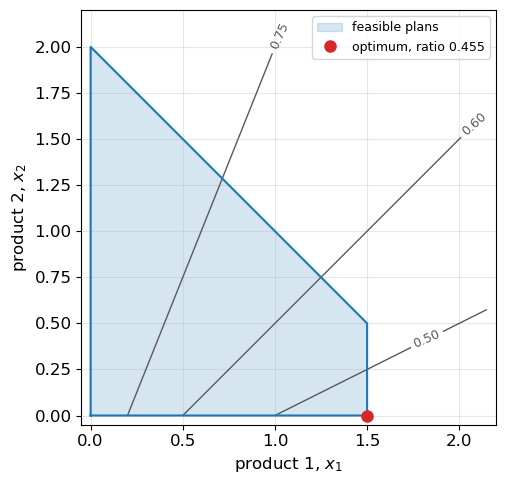

In [5]:
# The ratio is DQCP. Bisection and one Charnes–Cooper LP return the same plan.
c_rev = np.array([1.0, 2.0])
r_rev = np.array([3.0, 2.0])
alpha, beta = 1.0, 1.0

x = cp.Variable(2, nonneg=True)
ratio = (c_rev @ x + alpha) / (r_rev @ x + beta)
plan = cp.Problem(cp.Minimize(ratio), [cp.sum(x) <= 2, x[0] <= 1.5])
print(f"DCP {plan.is_dcp()}    DGP {plan.is_dgp()}    DQCP {plan.is_dqcp()}")
plan.solve(qcp=True, solver=cp.CLARABEL)
print(f"bisection  status {plan.status}    ratio {plan.value:.6f}    x {np.array2string(x.value, precision=4)}")

y = cp.Variable(2, nonneg=True)
t = cp.Variable(nonneg=True)
charnes = cp.Problem(
    cp.Minimize(c_rev @ y + alpha * t),
    [r_rev @ y + beta * t == 1, cp.sum(y) <= 2 * t, y[0] <= 1.5 * t],
)
charnes.solve(solver=cp.CLARABEL)
x_cc = y.value / t.value
print(f"linear program  ratio {charnes.value:.6f}    x {np.array2string(x_cc, precision=4)}    t {t.value:.4f}")

xx, yy = np.meshgrid(np.linspace(0, 2.15, 220), np.linspace(0, 2.15, 220))
level = (c_rev[0] * xx + c_rev[1] * yy + alpha) / (r_rev[0] * xx + r_rev[1] * yy + beta)
fig, ax = plt.subplots(figsize=(5.6, 5.0))
contour = ax.contour(xx, yy, level, levels=[0.5, 0.6, 0.75, 1.0], colors="0.35", linewidths=1.0)
ax.clabel(contour, fmt="%.2f", fontsize=9)
polygon = np.array([[0.0, 0.0], [1.5, 0.0], [1.5, 0.5], [0.0, 2.0]])
ax.fill(polygon[:, 0], polygon[:, 1], color="C0", alpha=0.18, label="feasible plans")
ax.plot(*np.vstack([polygon, polygon[:1]]).T, color="C0", lw=1.5)
ax.plot(x_cc[0], x_cc[1], "o", color="C3", ms=8, label=f"optimum, ratio {charnes.value:.3f}")
ax.set_aspect("equal")
ax.set_xlim(-0.05, 2.2)
ax.set_ylim(-0.05, 2.2)
ax.set_xlabel(r"product 1, $x_1$")
ax.set_ylabel(r"product 2, $x_2$")
ax.legend(fontsize=9, loc="upper right")
fig.tight_layout()
plt.show()


## What the firm produces

- The optimum is $(x_1,x_2)=(1.5,\, 0)$, and the ratio equals $2.5/5.5=5/11\approx 0.455$.

- Product 1 turns one unit of cost into three units of revenue. 
- Product 2 turns cost into revenue one for one, the same rate as doing nothing, whose ratio is $1/1=1$. 
- Producing product 2 cannot lower the ratio, at any feasible point. 
- The level curves on the slide are the sets of plans with a common ratio; the minimum on the polygon sits on the capacity of product 1, and the total-quantity constraint is slack.

- The bisection and the linear program agree. 
- The linear program is one cone program, so lecture 4's duality gap certifies it in a single solve. 
- The bisection is a sequence of feasibility problems. When a change of variables is available, take it.

`qcp=True` is the generic version of this idea: if every sublevel set $\{\mathbf{x}: f(\mathbf{x})\le \tau\}$ is a DCP constraint in $(\mathbf{x},\tau)$, CVXPy can bisect on $\tau$. You can also write that bisection yourself when the DQCP checker does not see the sublevel set and you do.


## Other quasiconvex and quasiconcave functions

A function is **quasiconvex** when every sublevel set is convex, and **quasiconcave** when every superlevel set is convex. Convexity implies quasiconvexity. The functions below are quasiconvex or quasiconcave and are not, in the form one writes them, convex.

- **Sharpe ratio.** Excess return $\boldsymbol{\mu}^\top\mathbf{x}$ divided by volatility $\|\Sigma^{1/2}\mathbf{x}\|_2$. On portfolios with positive excess return the ratio is quasiconcave. A fund ranks portfolios by return per unit of risk.
- **Condition number.** For $\mathbf{A}(\mathbf{x})\succ 0$ affine in $\mathbf{x}$, $\kappa(\mathbf{A})=\lambda_{\max}(\mathbf{A})/\lambda_{\min}(\mathbf{A})$. The ellipsoid $\{\mathbf{z}:\mathbf{z}^\top\mathbf{A}\mathbf{z}\le 1\}$ has longest axis over shortest axis equal to $\sqrt{\kappa(\mathbf{A})}$. Minimizing $\kappa$ asks that the worst direction be not much worse than the best. Experiment design, preconditioning, and the shape of a confidence set are this request.
- **Rank on the positive semidefinite cone.** For $\mathbf{X},\mathbf{Y}\succeq 0$, $\mathrm{rank}(\mathbf{X}+\mathbf{Y})\ge\max(\mathrm{rank}\,\mathbf{X},\mathrm{rank}\,\mathbf{Y})$, because the range of a summand sits inside the range of the sum. The superlevel sets $\{\mathbf{X}\succeq 0:\mathrm{rank}\,\mathbf{X}\ge k\}$ are convex, so rank is quasiconcave. The problem one usually wants is the other direction, minimize rank, and the sublevel sets $\{\mathrm{rank}\le k\}$ are not convex. Quasiconcavity does not hand that problem to the checker. The nuclear norm of lecture 2 is the tractable neighbour, and it is a different function.

## Integrality does not change the check

- Declare a variable `integer=True`. 
- The DCP checker still reports acceptance whenever the continuous relaxation is DCP. It never reads the flag.

The problem it accepts is no longer convex. 

- The feasible set $\{1.5, 2, 3, \ldots\}$ is not a convex set. 
- CLARABEL, pointed at the relaxation, returns $1.5$. 
- HiGHS, pointed at the integer program, branches and returns $2$.

The same split applies to any mixed-integer linear or second-order-cone program CVXPy can express: 
- the grammar describes the relaxation, and 
- branch-and-bound solver handles the integers. 

Mixed-integer programs sit outside the polynomial cone pipeline of lecture 4. 
An integer constraint on a nonconvex continuous problem is refused, because the relaxation already fails the checker.


In [6]:
# The checker accepts both. Only the relaxation is a convex problem.
n = 64
c = np.random.randn(n)
A = np.random.rand(n//4, n)
b = np.random.rand(n// 4)

x = cp.Variable(n, boolean=True)
problem = cp.Problem(cp.Minimize(c @ x), [A @ x <= 100*b])
problem.solve(solver=cp.MOSEK, verbose=True)



(CVXPY) Oct 18 12:16:56 PM: Your problem has 64 variables, 16 constraints, and 0 parameters.


(CVXPY) Oct 18 12:16:56 PM: It is compliant with the following grammars: DCP, DQCP


(CVXPY) Oct 18 12:16:56 PM: (If you need to solve this problem multiple times, but with different data, consider using parameters.)


(CVXPY) Oct 18 12:16:56 PM: CVXPY will first compile your problem; then, it will invoke a numerical solver to obtain a solution.


(CVXPY) Oct 18 12:16:56 PM: Your problem is compiled with the CPP canonicalization backend.


...

(CVXPY) Oct 18 12:17:06 PM: Optimal value: -1.141e+01


(CVXPY) Oct 18 12:17:06 PM: Compilation took 2.922e-03 seconds


(CVXPY) Oct 18 12:17:06 PM: Solver (including time spent in interface) took 1.005e+01 seconds


-------------------------------------------------------------------------------
                                    Summary                                    
-------------------------------------------------------------------------------


np.float64(-11.412832429556474)

## A relaxation is a different problem

Lectures 1 and 2 already replaced an objective the grammar cannot see.

**Examples**

- Cardinality $\|\mathbf{x}\|_0$, replaced by $\|\mathbf{x}\|_1$.
- Rank, replaced by the nuclear norm.
- A boolean quadratic, replaced by a positive-semidefinite lift. Lecture 1's MaxCut is that lift; the constraint rewrite is the next code.

**From relaxation to original problem**

- CVXPy solves the replacement. 
- It has no atom for the original. 
- The optimal value of the replacement is a bound on the original value. 
- The minimizer of the replacement is feasible for the original only under extra hypotheses, and those hypotheses are theorems, not a feature of the parser. 
- When the hypotheses fail, the two minimizers differ, as lecture 1 showed for basis pursuit.


## Refused, with nothing to rewrite

Four problems on which `is_dcp`, `is_dgp`, and `is_dqcp` are all false. No flag on `solve` changes that.

1. **An indefinite product.** $xy$ on free $(x,y)$ has an indefinite Hessian. No curvature attribute can be attached, so none of the three grammars has a rule.
2. **A signomial.** $a/b-b$ with $a,b>0$ is a difference of posynomials. The logarithm convexifies a posynomial inequality. It does not convexify a difference. Local sequential convex approximations exist; they are not this library.
3. **A non-affine equality.** $\|\mathbf{u}\|_2^2=1$ forces a convex constraint and its concave reverse at once. DCP allows an equality only when both sides are affine. The disk $\|\mathbf{u}\|_2^2\le 1$ is legal; the circle is not.
4. **Maximizing a convex function.** `sum_squares` is convex. The checker minimizes convex functions and maximizes concave ones.

Two further convex problems are refused because they have no graph implementation.

- **Copositive membership**, from lecture 4. The constraint is convex, and deciding it is co-NP-complete. An atom with a polynomial-time cone representation would collapse that.
- **Cardinality and rank as objectives.** No atom. The $\ell_1$ and nuclear-norm problems above are the legal neighbours, and they are different problems.

A fifth case never reaches the checker. An objective given by a simulator has no expression tree. There is nothing to walk, and no curvature to compose. Finite-difference methods and derivative-free search are outside this lecture.


In [7]:
# None of the three grammars accepts these.
def flags(name, problem):
    print(
        f"{name:<40} DCP {str(problem.is_dcp()):<5} "
        f"DGP {str(problem.is_dgp()):<5} DQCP {str(problem.is_dqcp()):<5}"
    )


x = cp.Variable()
y = cp.Variable()
flags("minimize xy on x + y = 1", cp.Problem(cp.Minimize(x * y), [x + y == 1, cp.abs(x) <= 1]))

a = cp.Variable(pos=True)
b = cp.Variable(pos=True)
flags("minimize a + b s.t. a/b - b <= 1", cp.Problem(cp.Minimize(a + b), [a / b - b <= 1]))

u = cp.Variable(2)
flags("minimize u0 s.t. ||u||^2 = 1", cp.Problem(cp.Minimize(u[0]), [cp.sum_squares(u) == 1]))
flags("maximize ||u||^2", cp.Problem(cp.Maximize(cp.sum_squares(u))))


minimize xy on x + y = 1                 DCP False DGP False DQCP False
minimize a + b s.t. a/b - b <= 1         DCP False DGP False DQCP False
minimize u0 s.t. ||u||^2 = 1             DCP False DGP False DQCP False
maximize ||u||^2                         DCP False DGP False DQCP False


## Lecture 1's MaxCut, rewritten

The previous cell refused an indefinite product, a non-affine equality, and the maximization of a convex function. Lecture 1's MaxCut is those three refusals in one problem. The spectrahedron is the rewrite that the checker accepts, and it describes a different problem.

For a graph with Laplacian $\mathbf{L}\succeq 0$,

$$
\mathrm{MaxCut}=\max_{\mathbf{x}\in\{\pm 1\}^n}\ \tfrac14\mathbf{x}^\top\mathbf{L}\mathbf{x}.
$$

CVXPy refuses the spelling `quad_form(x, L)` with `square(x) == 1`.

- $\mathbf{L}$ is a Laplacian, so $\mathbf{x}^\top\mathbf{L}\mathbf{x}$ is convex. The checker does not maximize a convex function.
- $x_i^2=1$ is not affine. It is the circle constraint, one copy per vertex.
- Expanded, edge $ij$ contributes $(1-x_i x_j)/2$, and $x_i x_j$ is an indefinite product.

The lift replaces the Gram matrix $\mathbf{x}\mathbf{x}^\top$ by a variable $\mathbf{X}$.

- $\tfrac14\mathbf{x}^\top\mathbf{L}\mathbf{x}=\tfrac14\langle\mathbf{L},\mathbf{x}\mathbf{x}^\top\rangle$ becomes $\tfrac14\mathrm{tr}(\mathbf{L}\mathbf{X})$, linear in $\mathbf{X}$. Maximizing a linear function is legal.
- $x_i^2=1$ becomes $X_{ii}=1$. That equality is affine. This is the whole change of constraint.
- $\mathbf{x}\mathbf{x}^\top\succeq 0$ and $\mathrm{rank}(\mathbf{X})=1$. The rank constraint is dropped. `PSD=True` keeps the cone.

Every $\pm 1$ vector gives a feasible $\mathbf{X}=\mathbf{x}\mathbf{x}^\top$, so the optimal value is an upper bound on the cut. A feasible $\mathbf{X}$ of rank greater than one is not a cut. The 5-cycle is small enough to enumerate the integer side.


In [8]:
# x_i^2 = 1 is refused. X_ii = 1 with X positive semidefinite is accepted.
n = 5
adjacency = np.zeros((n, n))
for i in range(n):
    adjacency[i, (i + 1) % n] = adjacency[(i + 1) % n, i] = 1.0
laplacian = np.diag(adjacency.sum(axis=1)) - adjacency

x = cp.Variable(n)
combinatorial = cp.Problem(
    cp.Maximize(0.25 * cp.quad_form(x, laplacian)),
    [cp.square(x) == 1],
)
print(
    f"±1 form          DCP {combinatorial.is_dcp()}   "
    f"DGP {combinatorial.is_dgp()}   DQCP {combinatorial.is_dqcp()}   "
    f"objective {cp.quad_form(x, laplacian).curvature}"
)

X = cp.Variable((n, n), PSD=True)
spectrahedron = cp.Problem(cp.Maximize(0.25 * cp.trace(laplacian @ X)), [cp.diag(X) == 1])
spectrahedron.solve(solver=cp.CLARABEL)

bits = (np.arange(1 << (n - 1))[:, None] >> np.arange(n - 1)) & 1
assignments = np.concatenate([2.0 * bits - 1.0, np.ones((len(bits), 1))], axis=1)
integer_cut = np.max(0.25 * np.einsum("bi,ij,bj->b", assignments, laplacian, assignments))
print(f"spectrahedron    DCP {spectrahedron.is_dcp()}   status {spectrahedron.status}")
print(f"SDP value {spectrahedron.value:.4f}    integer MaxCut {integer_cut:.0f}    ratio {integer_cut / spectrahedron.value:.3f}")
print(f"diagonal of X* {np.array2string(np.diag(X.value), precision=3)}    rank {np.linalg.matrix_rank(X.value, tol=1e-6)}")


±1 form          DCP False   DGP False   DQCP False   objective CONVEX
spectrahedron    DCP True   status optimal
SDP value 4.5225    integer MaxCut 4    ratio 0.884
diagonal of X* [1. 1. 1. 1. 1.]    rank 2


In [9]:
x = cp.Variable((n, 1))
X = cp.Variable((n, n), PSD=True)
combinatorial = cp.Problem(
    cp.Maximize(0.25 * cp.trace(laplacian @ X)),
    [cp.diag(X) == 1, 
     # X - cp.outer(x, x) >> 0
     cp.bmat([[X, x], [x.T, np.array([[1]])]]) >> 0,
    ],
)
print(
    f"product PSD form          DCP {combinatorial.is_dcp()}   "
    f"DGP {combinatorial.is_dgp()}   DQCP {combinatorial.is_dqcp()}   "
    f"objective {cp.quad_form(x, laplacian).curvature}"
)

try:
    combinatorial.solve(solver=cp.CLARABEL)
except cp.DCPError as err:
    print(err)
np.linalg.matrix_rank(X.value, tol=1e-6)

product PSD form          DCP True   DGP False   DQCP True   objective CONVEX


np.int64(2)

# Three models

- Each model below is DCP as written.
- Each one is a few atoms from the table.
- The interesting part is the domain object the solver returns: the change-points of a signal, the edges of a conditional-independence graph, and the cooling schedule of an office.


## A piecewise-constant signal

- A sensor records a quantity that holds one of four levels and jumps at three unknown times. 
- The record $\mathbf{y}\in\mathbb{R}^n$ is that quantity plus independent Gaussian noise.

- Let $D\mathbf{x}$ be the first difference, $(D\mathbf{x})_i = x_{i+1}-x_i$. 
- Total variation estimates the quantity by

$$
\begin{aligned}
\mathrm{minimize}_{\mathbf{x}}&\quad \tfrac12\|\mathbf{x}-\mathbf{y}\|_2^2 + \lambda\|D\mathbf{x}\|_1.
\end{aligned}
$$

`sum_squares` plus `norm(·, 1)` is DCP. 

- The absolute values become linear inequalities, and the fidelity stays a quadratic objective.

- The comparison is the same fidelity with a squared difference,

$$
\tfrac12\|\mathbf{x}-\mathbf{y}\|_2^2 + \mu\|D\mathbf{x}\|_2^2.
$$

- That penalty charges the square of every consecutive step.


noise std 0.28    true jumps after [34, 79, 119]
total variation lambda=4 relative error 0.153    residual std 0.301    jumps after [34, 79, 119]    heights [ 1.1  -1.52  0.76]
total variation lambda=1.5 relative error 0.076    residual std 0.267    jumps after [34, 79, 115, 119]    heights [ 1.15 -1.77  0.23  0.76]
squared difference mu=5.0 relative error 0.224    residual std 0.289    jumps after [34, 79, 80]    heights [ 0.21 -0.32 -0.24]
optimal value at lambda=4    12.71


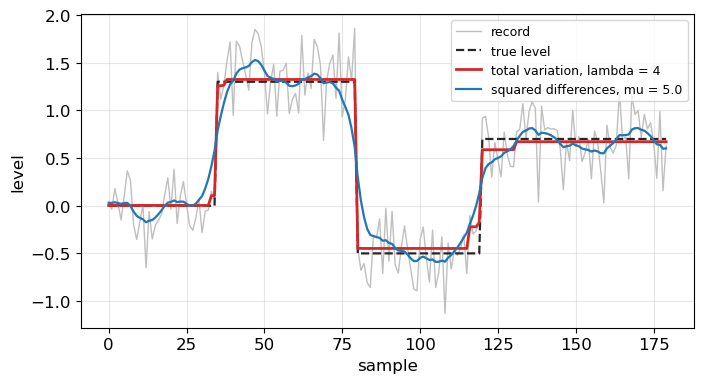

In [10]:
# ℓ1 on the first difference keeps the jumps. The squared difference spreads them.
n = 180
breaks = [0, 35, 80, 120, 180]
levels = [0.0, 1.3, -0.5, 0.7]
signal = np.concatenate([np.full(b - a, lev) for a, b, lev in zip(breaks[:-1], breaks[1:], levels)])
noise_std = 0.28
y = signal + rng.normal(0.0, noise_std, size=n)


def reconstruct(penalty, weight):
    estimate = cp.Variable(n)
    jump = estimate[1:] - estimate[:-1]
    problem = cp.Problem(cp.Minimize(0.5 * cp.sum_squares(estimate - y) + weight * penalty(jump)))
    problem.solve(solver=cp.CLARABEL)
    return estimate.value, problem.value

lambda_tv = 1.5
tv, tv_value = reconstruct(lambda jump: cp.norm(jump, 1), lambda_tv)
lambda_tv_small = 4
tv_small, _ = reconstruct(lambda jump: cp.norm(jump, 1), lambda_tv_small)
mu_smooth = 5.0
smooth, _ = reconstruct(lambda jump: cp.sum_squares(jump), mu_smooth)


def report(name, estimate):
    rel = np.linalg.norm(estimate - signal) / np.linalg.norm(signal)
    jumps = np.flatnonzero(np.abs(np.diff(estimate)) > 0.2)
    heights = np.diff(estimate)[jumps]
    print(
        f"{name:<18} relative error {rel:.3f}    "
        f"residual std {np.std(y - estimate):.3f}    "
        f"jumps after {jumps.tolist()}    heights {np.array2string(heights, precision=2)}"
    )


print(f"noise std {noise_std:.2f}    true jumps after {[b - 1 for b in breaks[1:-1]]}")
report(f"total variation lambda={lambda_tv_small}", tv_small)
report(f"total variation lambda={lambda_tv}", tv)
report(f"squared difference mu={mu_smooth}", smooth)
print(f"optimal value at lambda=4    {tv_value:.2f}")

fig, ax = plt.subplots()
ax.plot(y, color="0.75", lw=1.0, label="record")
ax.plot(signal, color="0.15", lw=1.6, ls="--", label="true level")
ax.plot(tv, color="C3", lw=2.0, label=f"total variation, lambda = {lambda_tv_small}")
ax.plot(smooth, color="C0", lw=1.6, label=f"squared differences, mu = {mu_smooth}")
ax.set_xlabel("sample")
ax.set_ylabel("level")
ax.legend(fontsize=9, loc="upper right")
fig.tight_layout()
plt.show()


## A conditional-independence graph

Let $\mathbf{z}\in\mathbb{R}^p$ be Gaussian with precision matrix $\Theta=\Sigma^{-1}$, and assume $\Theta$ is nonsingular. Then

$$
\Theta_{ij}=0 \quad\Longleftrightarrow\quad z_i \perp z_j \mid \mathbf{z}_{\setminus\{i,j\}}.
$$

The zero pattern of $\Theta$ is the conditional-independence graph. We observe $n$ independent samples, form the scatter matrix $S=\frac1n\sum_{k=1}^n \mathbf{z}^{(k)}(\mathbf{z}^{(k)})^\top$, and estimate $\Theta$ by the $\ell_1$-penalized Gaussian likelihood

$$
\begin{aligned}
\mathrm{maximize}_{\Theta}&\quad \log\det\Theta - \mathrm{tr}(S\Theta) - \lambda\sum_{i\neq j}|\Theta_{ij}|\\
\mathrm{subject\ to}&\quad \Theta\succeq 0.
\end{aligned}
$$

- `log_det` is concave, so maximizing it is legal. 
- The trace term is affine. 
- The off-diagonal $\ell_1$ term is convex, and it enters with a minus sign. 
- `Variable(PSD=True)` becomes a semidefinite constraint in `CvxAttr2Constr`. 
- The problem is DCP.

DCP True
status optimal
penalized likelihood
  4,5   -0.290  edge
  6,7   -0.237  edge
  0,1    0.233  edge
  5,6    0.194  edge
  3,4   -0.180  edge
  0,2    0.086  edge
  4,6    0.043      
  3,7    0.037      
  3,5   -0.036      
  1,2    0.018  edge
inverse scatter
  0,1    0.638  edge
  4,5   -0.426  edge
  6,7   -0.406  edge
  0,2    0.387  edge
  1,2    0.362  edge
  3,4   -0.289  edge
  5,6    0.247  edge
  0,4   -0.235      
  3,7    0.215      
  1,3   -0.190      
relative Frobenius    penalized 0.367    inverse scatter 0.316


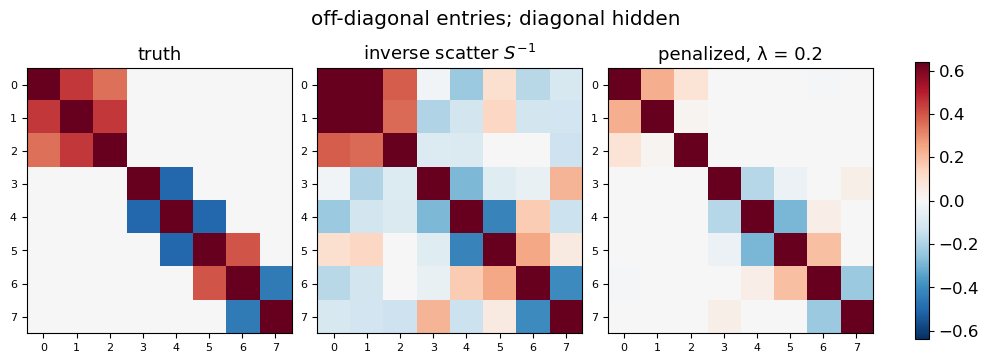

In [11]:
# The ℓ1 penalty ranks the seven true edges above every absent one.
p = 8
n_obs = 80
lam = 0.2
precision = np.eye(p)
true_edges = [(0, 1, 0.45), (1, 2, 0.45), (0, 2, 0.35), (3, 4, -0.50), (4, 5, -0.50), (5, 6, 0.40), (6, 7, -0.45)]
for i, j, value in true_edges:
    precision[i, j] = precision[j, i] = value
covariance = np.linalg.inv(precision)
samples = np.random.default_rng(0).multivariate_normal(np.zeros(p), covariance, size=n_obs)
scatter = samples.T @ samples / n_obs

theta = cp.Variable((p, p), PSD=True)
off_diagonal = np.ones((p, p))
np.fill_diagonal(off_diagonal, 0.0)
penalty = cp.sum(cp.multiply(off_diagonal, cp.abs(theta)))
likelihood = cp.log_det(theta) - cp.trace(scatter @ theta) - lam * penalty
graphical = cp.Problem(cp.Maximize(likelihood))
print(f"DCP {graphical.is_dcp()}")
graphical.solve(solver=cp.CLARABEL)
estimate = theta.value
sample_precision = np.linalg.inv(scatter)

true_set = {(i, j) for i, j, _ in true_edges}
upper = np.triu_indices(p, k=1)


def ranked(name, matrix, count=10):
    order = np.argsort(-np.abs(matrix[upper]))
    print(name)
    for rank in order[:count]:
        i, j = int(upper[0][rank]), int(upper[1][rank])
        tag = "edge" if (i, j) in true_set else "    "
        print(f"  {i},{j}  {matrix[i, j]:7.3f}  {tag}")


print(f"status {graphical.status}")
ranked("penalized likelihood", estimate)
ranked("inverse scatter", sample_precision)
rel_penalized = np.linalg.norm(estimate - precision) / np.linalg.norm(precision)
rel_sample = np.linalg.norm(sample_precision - precision) / np.linalg.norm(precision)
print(f"relative Frobenius    penalized {rel_penalized:.3f}    inverse scatter {rel_sample:.3f}")

def off_diagonal_view(matrix):
    view = matrix.astype(float).copy()
    np.fill_diagonal(view, np.nan)
    return view


panels = [
    (precision, "truth"),
    (sample_precision, r"inverse scatter $S^{-1}$"),
    (estimate, f"penalized, λ = {lam}"),
]
finite = np.concatenate([off_diagonal_view(matrix)[upper] for matrix, _ in panels])
vmax = np.max(np.abs(finite))
cmap = plt.cm.RdBu_r.copy()
cmap.set_bad("0.92")
fig, axes = plt.subplots(1, 3, figsize=(9.8, 3.6), constrained_layout=True)
for ax, (matrix, title) in zip(axes, panels):
    image = ax.imshow(matrix, cmap=cmap, vmin=-vmax, vmax=vmax)
    ax.set_title(title)
    ax.set_xticks(range(p))
    ax.set_yticks(range(p))
    ax.grid(False)
    ax.tick_params(labelsize=8)
fig.colorbar(image, ax=axes, shrink=0.86)
fig.suptitle("off-diagonal entries; diagonal hidden")
plt.show()


## Pre-cooling an office

- One room, one chiller. 
- The indoor temperature $T$ has time constant $\tau=5$ hours. 
- A kilowatt of cooling holds the room $R=2.2^\circ\mathrm{C}$ below the outdoor temperature $\theta$ at equilibrium,

$$
\tau \dot T=\theta(t)-T-R u.
$$

- On each hour, $\theta$ and the cooling power $u$ are constant. 
- The step is exact:

$$
T_{t+1}=a T_t+(1-a)\theta_t-R(1-a)u_t,\qquad a=e^{-1/\tau}.
$$

- The forecast is known, $\theta_t=28+8\sin\!\big(2\pi(t-9)/24\big)$. 
- It peaks at $36^\circ\mathrm{C}$ at 15:00. 
- At midnight, $T_0=23.5^\circ\mathrm{C}$. 
- From 08:00 to 18:00 the room must stay in $[21,\,24.5]$. 
- The chiller cannot exceed $8\,\mathrm{kW}$.

Electricity costs $0.15$ per kWh, and $0.70$ from 16:00 to 20:00. 
- Two objectives use the same constraints.
- One minimizes the kilowatt-hours, $\sum_t u_t$. 
- The other minimizes the bill, $\sum_t \pi_t u_t$.

Every step is an affine equality. The comfort band and the chiller bound are affine. Both objectives are affine. Each problem is DCP, with no rewrite. The same equalities with a $4\,\mathrm{kW}$ chiller are infeasible, which is a fact about the building and the forecast, not about the checker.


DCP True
chiller 4 kW      infeasible
minimum energy    33.48 kWh    bill 10.44    cooling at 16:00 5.10
minimum bill      38.24 kWh    bill  7.40    cooling at 16:00 0.00
saturated hours [13, 14, 15]    multipliers positive 3
bill plan at 16:00 21.00°C    at 18:00 24.50°C


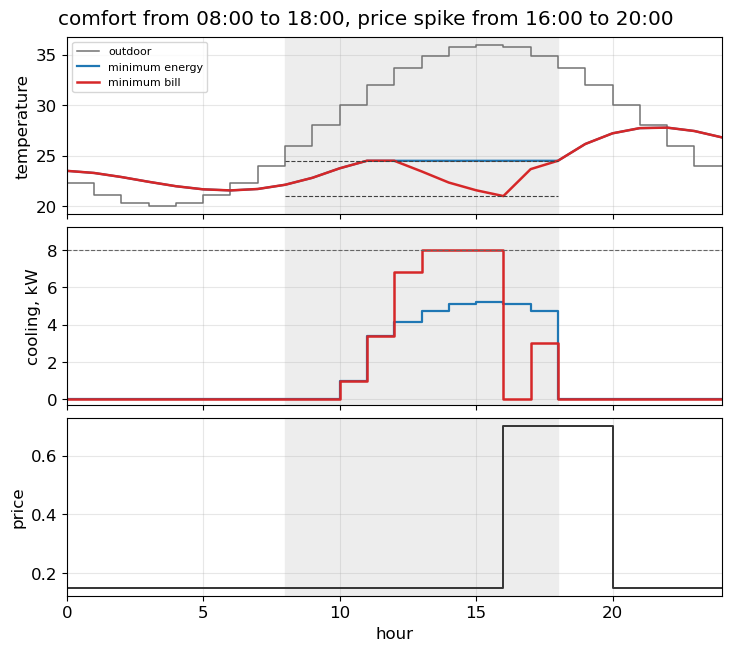

In [18]:
# Exact sampling of the thermal ODE. The chiller bound is an affine constraint on the input.
hours = np.arange(24)
outdoor = 28 + 8 * np.sin(2 * np.pi * (hours - 9) / 24)
time_constant = 5.0
resistance = 2.2
decay = np.exp(-1 / time_constant)
price = np.full(24, 0.15)
price[16:20] = 0.70


def office(objective, limit):
    temperature = cp.Variable(25)
    cooling = cp.Variable(24, nonneg=True)
    chiller = cooling <= limit
    constraints = [temperature[0] == 23.5, chiller]
    for t in range(hours.size):
        constraints.append(
            temperature[t + 1]
            == decay * temperature[t]
            + (1 - decay) * outdoor[t]
            - resistance * (1 - decay) * cooling[t]
        )
    constraints += [temperature[8:19] >= 21, temperature[8:19] <= 24.5]
    cost = cp.sum(cooling) if objective == "energy" else price @ cooling
    problem = cp.Problem(cp.Minimize(cost), constraints)
    problem.solve(solver=cp.CLARABEL)
    return problem, temperature.value, cooling.value, chiller


small, *_ = office("bill", 4)
energy, temperature_energy, cooling_energy, _ = office("energy", 8)
bill, temperature_bill, cooling_bill, chiller = office("bill", 8)
multipliers = np.asarray(chiller.dual_value).ravel()
saturated = cooling_bill >= 8 - 1e-3

print(f"DCP {bill.is_dcp()}")
print(f"chiller 4 kW      {small.status}")
print(
    f"minimum energy    {cooling_energy.sum():5.2f} kWh"
    f"    bill {price @ cooling_energy:5.2f}"
    f"    cooling at 16:00 {cooling_energy[16]:.2f}"
)
print(
    f"minimum bill      {cooling_bill.sum():5.2f} kWh"
    f"    bill {price @ cooling_bill:5.2f}"
    f"    cooling at 16:00 {cooling_bill[16]:.2f}"
)
print(
    f"saturated hours {np.where(saturated)[0].tolist()}"
    f"    multipliers positive {int(np.sum(multipliers > 1e-3))}"
)
print(
    f"bill plan at 16:00 {temperature_bill[16]:.2f}°C"
    f"    at 18:00 {temperature_bill[18]:.2f}°C"
)

clock = np.arange(25)
fig, axes = plt.subplots(3, 1, figsize=(7.2, 6.4), sharex=True, constrained_layout=True)
for ax in axes:
    ax.axvspan(8, 18, color="0.93", zorder=0)
axes[0].step(np.append(hours, 24), np.append(outdoor, outdoor[-1]), where="post", color="0.45", lw=1.1, label="outdoor")
axes[0].plot(clock, temperature_energy, color="C0", lw=1.6, label="minimum energy")
axes[0].plot(clock, temperature_bill, color="C3", lw=1.8, label="minimum bill")
axes[0].plot([8, 18], [21, 21], color="0.25", lw=0.8, ls="--")
axes[0].plot([8, 18], [24.5, 24.5], color="0.25", lw=0.8, ls="--")
axes[0].set_ylabel("temperature")
axes[0].legend(fontsize=8, loc="upper left")
axes[1].step(np.append(hours, 24), np.append(cooling_energy, cooling_energy[-1]), where="post", color="C0", lw=1.6)
axes[1].step(np.append(hours, 24), np.append(cooling_bill, cooling_bill[-1]), where="post", color="C3", lw=1.8)
axes[1].axhline(8, color="0.4", lw=0.8, ls="--")
axes[1].set_ylabel("cooling, kW")
axes[1].set_ylim(-0.3, 9.2)
axes[2].step(np.append(hours, 24), np.append(price, price[-1]), where="post", color="0.2", lw=1.4)
axes[2].set_ylabel("price")
axes[2].set_xlabel("hour")
axes[2].set_xlim(0, 24)
fig.suptitle("comfort from 08:00 to 18:00, price spike from 16:00 to 20:00")
plt.show()


## What the cooling schedule says

A $4\,\mathrm{kW}$ chiller cannot hold this office on this forecast. 
- The problem is infeasible. 
- Every power in $[0,\,4]$ was already admitted by the bound, and no sequence of them keeps the room inside $[21,\,24.5]$ from 08:00 to 18:00.

With an $8\,\mathrm{kW}$ chiller both plans are feasible, and they do different things. 

**Energy minimization**

- Minimum energy uses $33.5\,\mathrm{kWh}$. 
- It parks the room on the ceiling, $24.5^\circ\mathrm{C}$, and it is still drawing about $5\,\mathrm{kW}$ at 16:00, the first hour of the spike. 
- The bill is $10.44$. 

**Cost minimization**

- Minimum bill uses $38.2\,\mathrm{kWh}$. 
- The chiller sits on $8\,\mathrm{kW}$ from 13:00 to 16:00. At 16:00 the room is on the floor, $21^\circ\mathrm{C}$, and the chiller is off. 
- It comes back at about $3\,\mathrm{kW}$ over the next hour, and at 18:00 the room is on the ceiling again. 
- The bill is $7.40$. 
- The extra kilowatt-hours are bought at $0.15$, and the first hour of the spike is met from the thermal mass.

## Takeaway

1. CVXPy is the grammar of lecture 2 and the cone reduction of lecture 4, followed by a solver. The intermediate objects are the expression tree, a canonicalization, and a primal-dual pair. `dual_value` is meaningful on the constraint whose perturbation you can name.
2. A problem is accepted as written when every atom is known and the composition rules hold. The cones that come out are the orthant, the second-order cone, the exponential cone, the power cone, and the positive semidefinite cone.
3. Some problems become the same minimization after a rewrite. 
4. A relaxation is a different problem. The $\ell_1$ norm, the nuclear norm, and a semidefinite lift are legal, and cardinality, rank, and a boolean quadratic are not. MaxCut is the worked lift: $x_i^2=1$ is refused, and $X_{ii}=1$ with $\mathbf{X}\succeq 0$ is accepted.
5. An indefinite product, a signomial, a non-affine equality, the maximization of a convex function, a copositive constraint, and a simulator with no expression tree are refused.
6. In the three models the useful output was a domain object. 
    - Total variation returned the three change-points of the record. 
    - The penalized Gaussian likelihood returned the conditional-independence graph, with magnitudes shrunk. 
    - The cooling schedule for an office


### References

- **Software.** S. Diamond and S. Boyd, [*CVXPY: a Python-embedded modeling language for convex optimization*](https://jmlr.org/papers/v17/15-408.html), JMLR 2016. The pipeline in this lecture is that paper's canonicalization, followed by a cone solver.
- **Rewriting.** A. Agrawal, R. Verschueren, S. Diamond, and S. Boyd, [*A rewriting system for convex optimization problems*](https://web.stanford.edu/~boyd/papers/cvxpy_rewriting.html), Journal of Control and Decision, 2018. `Dcp2Cone` and the graph implementations are this rewrite system. `Dgp2Dcp` is a front end for it.
- **Grammars.** M. Grant, S. Boyd, and Y. Ye, [*Disciplined convex programming*](https://web.stanford.edu/~boyd/papers/pdf/disc_cvx_prog.pdf). A. Agrawal, S. Diamond, and S. Boyd, [*Disciplined geometric programming*](https://web.stanford.edu/~boyd/papers/dgp.html), Optimization Letters, 2019. A. Agrawal and S. Boyd, [*Disciplined quasiconvex programming*](https://web.stanford.edu/~boyd/papers/dqcp.html), Optimization Letters, 2020. The three checkers in the code are these three papers.
- **Book.** S. Boyd and L. Vandenberghe, [*Convex Optimization*](https://web.stanford.edu/~boyd/cvxbook/), §4.5 for geometric programs and the log change of variables, §4.3 for the second-order representation of $t\ge 1/x$. The [atom list](https://www.cvxpy.org/tutorial/dcp/index.html) is the corresponding CVXPy page.
- **Ratio.** A. Charnes and W. W. Cooper, [*Programming with linear fractional functionals*](https://doi.org/10.1002/nav.3800090303), Naval Research Logistics Quarterly, 1962.
- **Total variation.** L. I. Rudin, S. Osher, and E. Fatemi, [*Nonlinear total variation based noise removal algorithms*](https://doi.org/10.1016/0167-2789(92)90242-F), Physica D, 1992. The 1D problem on the slide is their fidelity-plus-total-variation model with a squared loss.
- **MaxCut.** Lecture 1. M. Goemans and D. Williamson, [*Improved approximation algorithms for maximum cut and satisfiability problems using semidefinite programming*](https://math.mit.edu/~goemans/PAPERS/maxcut-jacm.pdf), J. ACM, 1995. The DCP form in this lecture is their spectrahedron: unit diagonal, $\mathbf{X}\succeq 0$, linear objective.
- **Pre-cooling.** F. Oldewurtel, A. Parisio, C. N. Jones, et al., [*Use of model predictive control and weather forecasts for energy efficient building climate control*](https://doi.org/10.1016/j.enbuild.2011.09.022), Energy and Buildings, 2012. The slide is one day of that model: a linear thermal step, a comfort band, a chiller bound, and a known price.
- **Quasiconvex objectives.** S. Boyd and L. Vandenberghe, [*Convex Optimization*](https://web.stanford.edu/~boyd/cvxbook/), §3.4 for quasiconvex functions and §4.2.5 for optimization by bisection.
- **Cones.** MOSEK ApS, [*MOSEK Modeling Cookbook*](https://docs.mosek.com/modeling-cookbook/index.html), chapters 2–6: which modeling pattern lands in which cone. The delay budget is their pattern for the reciprocal.
